# Chimera training — iteration workflow

End-to-end demonstration of the `training/` iteration loop:

1. Build a reproducible 2-species subset (`training/build_subset.py`).
2. Train with the pre-registered workflow (`training/train_and_diagnose.py`).
3. Check every pre-registered expectation (`training/check_expectations.py`).
4. Visualise the outputs that matter (alpha trajectory, Δα distribution, loss components).

Full workflow rationale and the expectation table live in [`../training/workflow.md`](../training/workflow.md).

**Settings used** (from iteration findings documented in the changelog):
- `hidden_activation="tanh"` in the GIN (default after 2026-04-17 — ReLU blocks positive Δα architecturally).
- `adv_weight=100` (beyond spec's {0.03, 0.1, 0.3} sweep; needed because Chimera's `.sum(-1).mean()` reconstruction scales L_recon to ~10³ while scvi-tools' cross-entropy adversarial is bounded by log(K) ≈ 0.7 — a four-order-of-magnitude gap on z-gradient).
- `lambda_fit=0.05` (spec sweep top end).
- `warmup_adversarial_epochs=5` (earlier than spec's 15, so adv pushes back before the encoder fully commits to species-in-z).

In [1]:
import subprocess, sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, anndata as ad

REPO = Path().resolve().parent
RUN_NAME = 'iter31-mmd1k-masked-detached'  # adjust to the run you want to analyse
RUN_DIR = REPO / 'training' / 'runs' / RUN_NAME

## 1. Build the subset

Only run once per dataset choice. The script:
- Subsets `camex_pancreas_unified.h5ad` to the chosen species.
- Drops genes with fewer than 3 expressing cells in the subset.
- **Recomputes** `uns['p_null']` on the subset (species-dependent).
- Writes metadata JSON alongside the h5ad.

Note: before first use, run `python ../training/recompute_esm2_variance.py` once on the *full* unified AnnData to populate `varm['gene_features'][:, 64]` (the ESM-2 inter-species variance was all zeros in the shipped data — see CHANGELOG entry for 2026-04-17).

In [2]:
# Run once; uncomment to regenerate
# !python ../training/build_subset.py --species Human Monkey

## 2. Launch a training iteration

Prefer running this from the shell so the progress bar is usable; then come back for analysis.

In [3]:
# !python ../training/train_and_diagnose.py \
#   --run-name final-tanh-200ep \
#   --max-epochs 200 \
#   --adv-weight 100 --lambda-fit 0.05 \
#   --warmup-adversarial-epochs 5 \
#   --snapshot-every-n-epochs 10

## 3. Check expectations

In [4]:
out = subprocess.run([sys.executable, str(REPO/'training/check_expectations.py'), '--run-name', RUN_NAME],
                     capture_output=True, text=True)
print(out.stdout)

# Expectations Report — `iter31-mmd1k-masked-detached`

- Config: D
- Max epochs (requested): 100
- Adata: data/processed/camex_human_monkey.h5ad
- Started: 2026-04-18T11:13:04

| ID | Name | Category | Value | Threshold | Pass |
|---|---|---|---|---|---|
| E1.1 | E1.1_conservation_signal | E1 pretraining | 0.0830 | r>=0.02 OR (|r|<0.15 AND prior_std>=0.05) | ✓ |
| E1.2 | E1.2_gene_features_normalized | E1 pretraining | {'n_active_features': 69, 'n_padding_or_dead_features': 3, 'active_mean_abs_max': 0.05249284580349922, 'active_std_min': 0.9314808249473572, 'active_std_max': 1.0167803764343262, 'pass': True, 'notes': 'Zero-std features are treated as padding/dead and excluded.'} | — | ✓ |
| E1.3 | E1.3_p_null_dynamic_range | E1 pretraining | 0.6712 | 0.5 | ✓ |
| E1.4 | E1.4_batch_to_species_unique | E1 pretraining | {'max_species_per_batch': 1, 'pass': True} | — | ✓ |
| E1.5 | E1.5_conservation_prior_range | E1 pretraining | {'min': 0.16378170251846313, 'max': 0.949999988079071, 'std'

## 4. Visualise the outputs

### 4.1 Alpha trajectory over training

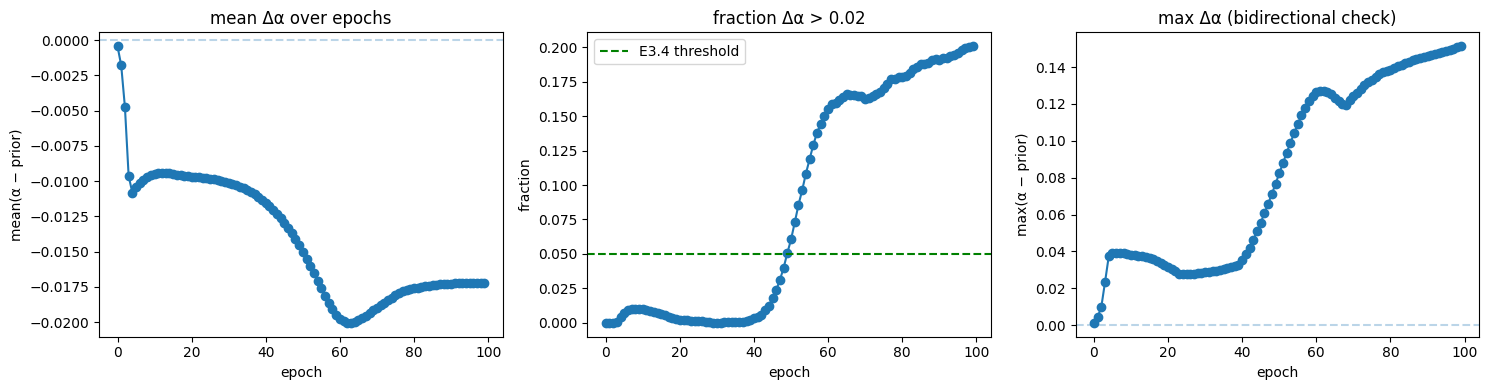

In [5]:
snap_dir = RUN_DIR / 'alpha_snapshots'
snaps = sorted(snap_dir.glob('alpha_epoch_*.npz'))
epochs, mean_deltas, frac_pos, max_deltas = [], [], [], []
for p in snaps:
    d = np.load(p)
    delta = d['alpha'] - d['prior']
    epochs.append(int(d['epoch']))
    mean_deltas.append(float(delta.mean()))
    frac_pos.append(float((delta > 0.02).mean()))
    max_deltas.append(float(delta.max()))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(epochs, mean_deltas, marker='o'); ax[0].axhline(0, ls='--', alpha=0.3)
ax[0].set(title='mean Δα over epochs', xlabel='epoch', ylabel='mean(α − prior)')
ax[1].plot(epochs, frac_pos, marker='o'); ax[1].axhline(0.05, ls='--', color='green', label='E3.4 threshold')
ax[1].set(title='fraction Δα > 0.02', xlabel='epoch', ylabel='fraction'); ax[1].legend()
ax[2].plot(epochs, max_deltas, marker='o'); ax[2].axhline(0, ls='--', alpha=0.3)
ax[2].set(title='max Δα (bidirectional check)', xlabel='epoch', ylabel='max(α − prior)')
plt.tight_layout(); plt.show()

### 4.2 Final Δα distribution vs conservation prior

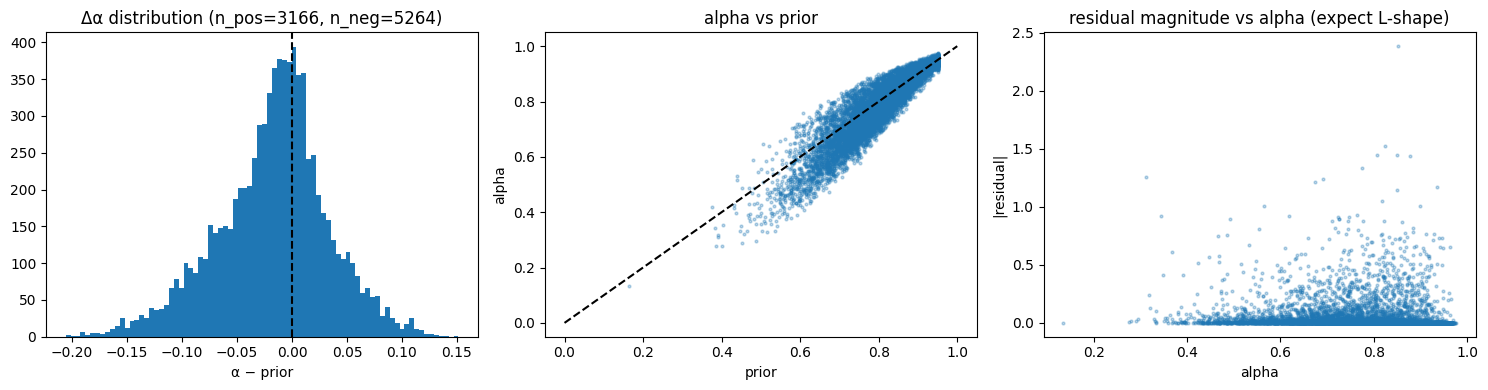

In [6]:
fs = dict(np.load(RUN_DIR / 'final_state.npz'))
prior = fs['prior']; alpha = fs['alpha']; delta = alpha - prior
resid = fs['residual_mean_abs']

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(delta, bins=80); ax[0].axvline(0, ls='--', color='k')
ax[0].set(title=f'Δα distribution (n_pos={int((delta>0).sum())}, n_neg={int((delta<0).sum())})',
          xlabel='α − prior')
ax[1].scatter(prior, alpha, s=4, alpha=0.3); ax[1].plot([0,1],[0,1],'k--')
ax[1].set(title='alpha vs prior', xlabel='prior', ylabel='alpha')
ax[2].scatter(alpha, resid, s=4, alpha=0.3)
ax[2].set(title='residual magnitude vs alpha (expect L-shape)', xlabel='alpha', ylabel='|residual|')
plt.tight_layout(); plt.show()

### 4.3 Loss components over training

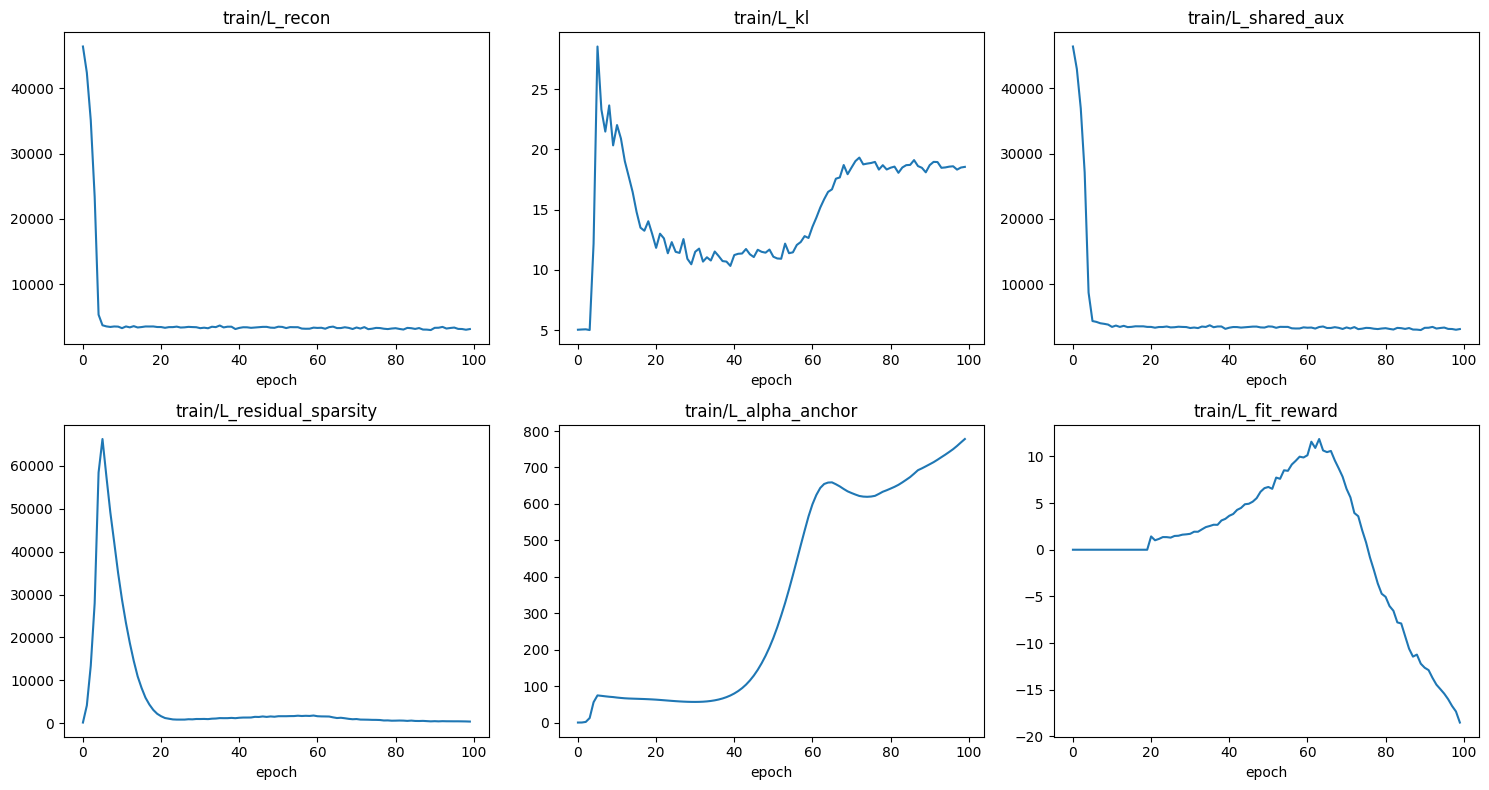

In [7]:
csv = next((RUN_DIR/'lightning').rglob('metrics.csv'))
df = pd.read_csv(csv)
per_ep = df.groupby('epoch').last()

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for i, col in enumerate(['train/L_recon','train/L_kl','train/L_shared_aux','train/L_residual_sparsity','train/L_alpha_anchor','train/L_fit_reward']):
    a = ax[i//3][i%3]
    if col in per_ep: a.plot(per_ep.index, per_ep[col])
    a.set(title=col, xlabel='epoch')
plt.tight_layout(); plt.show()

### 4.4 z-leakage audit

A logistic regression on `z_mean` that can perfectly separate species means the shared
decoder (which uses `z.detach()`) can still read species off z in its forward pass,
contaminating FQR. Target: accuracy near `1/K`.

In [8]:
from sklearn.linear_model import LogisticRegression
clf = LogisticRegression(max_iter=500).fit(fs['z_mean'], fs['species_labels'])
print(f'LogReg species accuracy on z: {clf.score(fs["z_mean"], fs["species_labels"]):.4f}')
print(f'  (chance = {1.0/int(fs["n_species"]):.3f}; spec expectation ≤ 0.55 for 2 species)')

LogReg species accuracy on z: 0.6977
  (chance = 0.500; spec expectation ≤ 0.55 for 2 species)


## Closing the loop

If any expectation failed, consult [`../training/workflow.md`](../training/workflow.md)
section "Common coupled-failure patterns" for a first-suspect list. Do not bundle
fixes in one iteration — each change should be attributable to a specific failed
expectation so the next report can tell you whether that particular intervention
helped.